In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from statsmodels.regression.linear_model import yule_walker
from spectrum import pyule, aryule, pburg, arburg
from scipy.signal import windows
from datetime import datetime

rc({"text.usetex": True
    ,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 12})

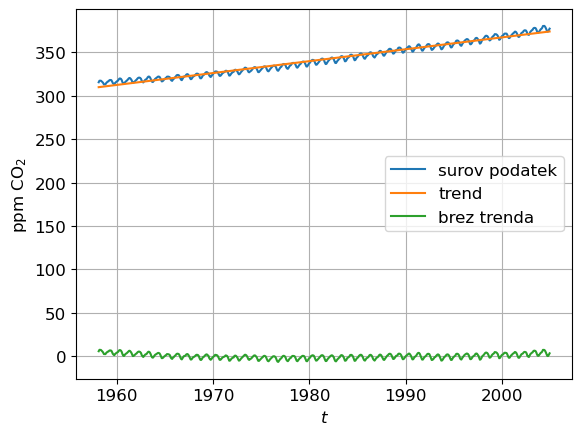

In [4]:
leto,co2=np.loadtxt('podatki/co2.dat',unpack=True)
co2[co2==-99.99]= np.nan #missing value
nan_indices = np.isnan(co2)
leto = leto[~nan_indices]
co2 = co2[~nan_indices]

k=np.polyfit(leto,co2,deg=1)
poli=np.poly1d(k)
lin_trend=poli(leto)
data = co2 - lin_trend

plt.plot(leto,co2, label='surov podatek')
plt.plot(leto, lin_trend,label='trend')
plt.plot(leto, data,label='brez trenda')
plt.legend()
plt.xlabel('$t$')
plt.ylabel('ppm CO$_2$')
plt.grid()
#plt.savefig('slike/co2_potek_trend.pdf')

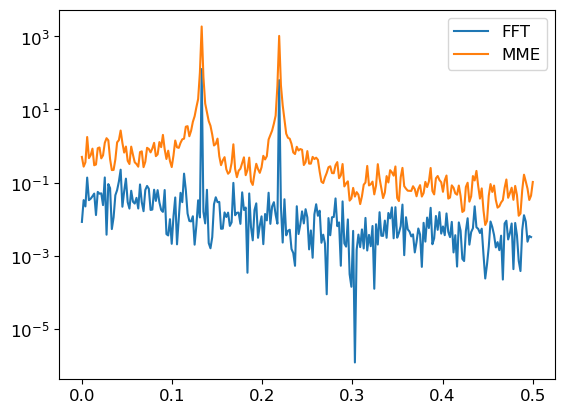

In [5]:
data = np.loadtxt('podatki/val2.dat')
t = np.linspace(0,len(data),len(data))
dim= len(data) #vedno 512

fourier = np.fft.fft(data)
freq = np.fft.fftfreq(dim)
PSD_f = np.abs(fourier)**2/dim

# G = 1
# a_k, residual = yule_walker(data, order=50)
# omega = 2*np.pi*np.fft.fftfreq(dim)
# r=0
# for k in range(len(a_k)):
#     r+=a_k[k] * np.exp(-1j * k * omega)
# H = G*G/np.abs(1 + r)**2

p = pyule(data, order=200)
p.run()
px= p.get_converted_psd(sides='onesided')/dim
fx=p.frequencies(sides='onesided')

plt.plot(freq[:dim//2], PSD_f[:dim//2], label='FFT')
#plt.plot(omega[:dim//2]/2/np.pi, H[:dim//2], label='MME')
plt.plot(fx, px, label='MME') #modul!!!
plt.yscale('log')
plt.legend()

In [6]:
def PSD(val,order, okno=None, plot=True, burg=False):
    data = np.loadtxt('podatki/val'+str(val)+'.dat')
    dim= len(data) #vedno 512
    
    if okno is not None:
        window = getattr(windows, okno)(dim)
        data = data * window

    if burg:
        p = pburg(data, order=order)
    else:
        p = pyule(data, order=order)
    p.run()
    px = p.get_converted_psd(sides='onesided')/dim
    fx = p.frequencies(sides='onesided')

    # nerelevantno za PSD!
    # a,_,_ = aryule(data, order=order)
    # z =  np.roots(np.concatenate(([1], -a))) #poli (ničle v imenovalcu)
    # n=0
    # for i in range(len(z)):
    #     r=np.abs(z[i])
    #     if r>1 and mirror != 0:
    #         n+=1
    #         if mirror==1:
    #             z[i] = 1 / z[i].conjugate() #mirror
    #         else:
    #             z[i] = z[i] / np.abs(z[i]) #on unit circle
    # print(f'{n} ničel od {order} je izven enotkega kroga')
    
    if plot:
        plt.plot(fx, px, label='$p=$'+str(order), linewidth=1.5, alpha=0.7)        
    return px
def PSD_co2(order, korak=1,okno=None, plot=True, trend=False, burg=False):
    time, data = np.loadtxt('podatki/co2.dat', unpack=True)
    data[data==-99.99]= np.nan #missing value
    nan_indices = np.isnan(data)
    time = time[~nan_indices]
    data = data[~nan_indices]
    time = time[::korak]
    data = data[::korak]
    # time = time[:len(time)//korak]
    # data = data[:len(time)//korak]
    dim= len(data)
    dt = time[1]-time[0]

    if trend:
        k=np.polyfit(time,data,deg=1)
        poli=np.poly1d(k)
        lin_trend=poli(time)
        data = data - lin_trend
    
    if okno is not None:
        window = getattr(windows, okno)(dim)
        data = data * window

    if burg:
        p = pburg(data, order=order)
    else:
        p = pyule(data, order=order)
    p.run()
    px = p.get_converted_psd(sides='onesided')[:-1] / dim
    fx = p.frequencies(sides='onesided')
    fx = np.fft.fftfreq(dim, d=dt)[:dim//2]

    # a,_,_ = aryule(data, order=order)
    # z =  np.roots(np.concatenate(([1], -a))) #poli (ničle v imenovalcu)
    # n=0
    # for i in range(len(z)):
    #     r=np.abs(z[i])
    #     if r>1 and mirror != 0:
    #         n+=1
    #         if mirror==1:
    #             z[i] = 1 / z[i].conjugate() #mirror
    #         else:
    #             z[i] = z[i] / np.abs(z[i]) #on unit circle
    # print(f'{n} ničel od {order} je izven enotkega kroga')

    if plot:
        plt.plot(fx, px, label='$p=$'+str(order), linewidth=1.5, alpha=0.7)        
    return px

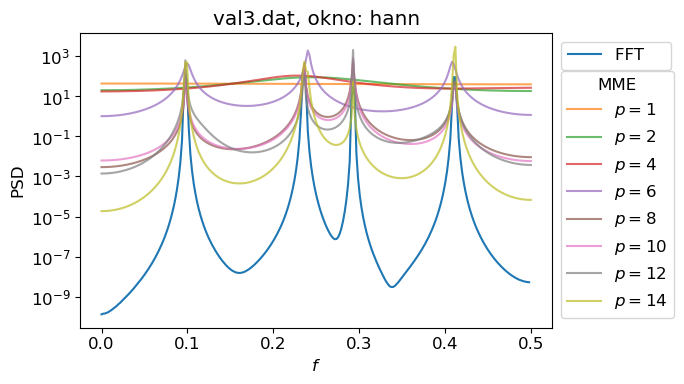

In [7]:
val = 3
okno = 'hann'
#okno = None

plt.figure(figsize=(7,4))
data = np.loadtxt('podatki/val'+str(val)+'.dat')
dim=len(data)
if okno is not None:
    fourier = np.fft.fft(data*getattr(windows, okno)(dim))
else:
    fourier = np.fft.fft(data)
freq = np.fft.fftfreq(dim)
PSD_f = np.abs(fourier[:dim//2])**2/dim
plt.plot(freq[:dim//2], PSD_f)
    
for order in range(0,15,2):
    if order==0:
        order=1
    PSD(val,order,okno, burg=False)

plt.yscale('log')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='C0', linestyle='-', label='FFT    ')],
                                bbox_to_anchor=(1.27,1))
plt.gca().add_artist(legend_line_styles)
plt.legend(title='MME', bbox_to_anchor=(1,0.9))
if okno is not None:
    plt.title('val'+str(val)+'.dat, okno: '+okno)
else:
    plt.title('val'+str(val)+'.dat, brez okna')
plt.xlabel('$f$')
plt.ylabel('PSD')
plt.tight_layout()
#plt.savefig('slike/PSD_val'+str(val)+'_'+okno+'.pdf')

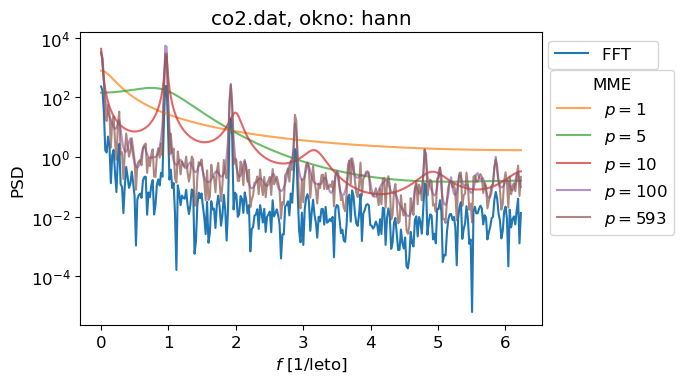

In [6]:
okno = 'hann'
#okno = None
trend=True

plt.figure(figsize=(7,4))
time, data = np.loadtxt('podatki/co2.dat',unpack=True)

data[data==-99.99]= np.nan #missing value
nan_indices = np.isnan(data)
time = time[~nan_indices]
data = data[~nan_indices]

if trend:
    k=np.polyfit(time,data,deg=1)
    poli=np.poly1d(k)
    lin_trend=poli(leto)
    data = data - lin_trend

dim=len(data)
dt = time[1] - time[0]
if okno is not None:
    fourier = np.fft.fft(data*getattr(windows, okno)(dim))
else:
    fourier = np.fft.fft(data)
freq = np.fft.fftfreq(dim, d=dt)
PSD_f = np.abs(fourier[:dim//2])**2/dim
plt.plot(freq[:dim//2], PSD_f)

primeri = [1,5,10,100,dim-11]
for order in primeri:
    if order==0:
        order=1
    PSD_co2(order,okno=okno, trend=trend, burg=False)
#PSD_co2(order=dim-1, okno=okno)

plt.yscale('log')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='C0', linestyle='-', label='FFT    ')],
                                bbox_to_anchor=(1.27,1))
plt.gca().add_artist(legend_line_styles)
plt.legend(title='MME', bbox_to_anchor=(1,0.9))
if okno is not None:
    plt.title('co2.dat, okno: '+okno)
else:
    plt.title('co2.dat, brez okna')
plt.xlabel('$f$ [1/leto]')
plt.ylabel('PSD')
plt.tight_layout()
#plt.savefig('slike/PSD_co2_brez_trend_'+okno+'.pdf')

# napaka

In [7]:
val = 2
okno = 'hann'
okno = None

data = np.loadtxt('podatki/val'+str(val)+'.dat')
dim=len(data)
if okno is not None:
    fourier = np.fft.fft(data*getattr(windows, okno)(dim))
else:
    fourier = np.fft.fft(data)
freq = np.fft.fftfreq(dim)
PSD_f = np.abs(fourier[:dim//2])**2/dim

err=[]
err_log=[]
p = np.arange(1,dim,step=1,dtype=int)
for order in p:
    if order==0:
        order=1
    PSD_MME = PSD(val,order,okno,plot=False)
    napaka = PSD_MME[:-1] - PSD_f #shape!
    napaka_r = np.abs(np.sum(napaka)/np.sum(PSD_f))
    napaka_log = np.log10(PSD_MME[:-1] - PSD_f) #logaritmična napaka
    napaka_log_r = np.abs(np.sum(napaka)/np.sum(np.log10(PSD_f)))
    err.append(napaka_r)
    err_log.append(napaka_log_r)

/tmp/ipykernel_622005/1404395595.py:23: RuntimeWarning: invalid value encountered in log10
  napaka_log = np.log10(PSD_MME[:-1] - PSD_f) #logaritmična napaka


KeyboardInterrupt: 

minimum napake: 7.659096876084724 , pri p = 7


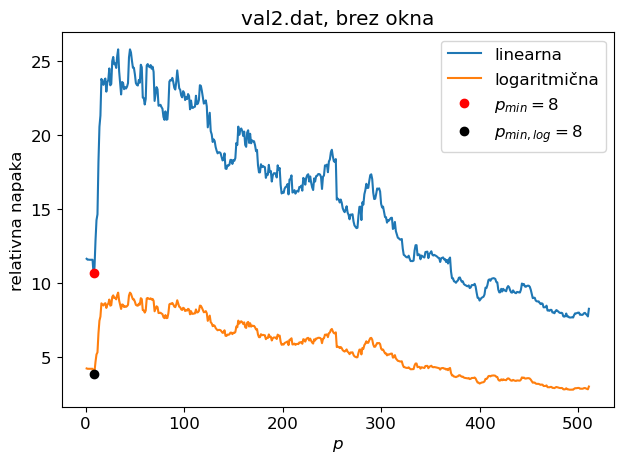

In [ ]:
p_min = err.index(min(err))
p_min_log = err_log.index(min(err_log))
if True:
    p_min = err.index(min(err[:dim//2]))
    p_min_log = err_log.index(min(err_log[:dim//2]))
print('minimum napake:', min(err), ', pri p =', p_min)
plt.plot(p,err,label='linearna')
plt.plot(p,err_log,label='logaritmična')
plt.plot(p[p_min], err[p_min], 'ro', label='$p_{min} = $'+str(p[p_min]))
plt.plot(p[p_min_log], err_log[p_min_log], 'ko', label='$p_{min,log} = $'+str(p[p_min_log]))
plt.xlabel('$p$')
plt.ylabel('relativna napaka')
plt.legend()
plt.yscale('linear')
plt.xscale('linear')
if okno is not None:
    plt.title('val'+str(val)+'.dat, okno: '+okno)
    plt.tight_layout()
    #plt.savefig('slike/napaka_val'+str(val)+'_'+okno+'.pdf')
else:
    plt.title('val'+str(val)+'.dat, brez okna')
    plt.tight_layout()
    #plt.savefig('slike/napaka_val'+str(val)+'.pdf')

In [ ]:
okno = 'hann'
#okno = None
trend=True

time, data = np.loadtxt('podatki/co2.dat',unpack=True)
data[data==-99.99]= np.nan #missing value
nan_indices = np.isnan(data)
time = time[~nan_indices]
data = data[~nan_indices]

if trend:
    k=np.polyfit(time,data,deg=1)
    poli=np.poly1d(k)
    lin_trend=poli(leto)
    data = data - lin_trend
dim=len(data)
dt = time[1] - time[0]

if okno is not None:
    fourier = np.fft.fft(data*getattr(windows, okno)(dim))
else:
    fourier = np.fft.fft(data)

freq = np.fft.fftfreq(dim, d=dt)
PSD_f = np.abs(fourier[:dim//2])**2/dim

err=[]
err_log=[]
p = np.arange(1,dim-1,step=1,dtype=int)
for order in p:
    if order==0:
        order=1
    PSD_MME = PSD_co2(order,okno=okno,plot=False,trend=trend)
    napaka = PSD_MME - PSD_f #shape!
    napaka_r = np.abs(np.sum(napaka)/np.sum(PSD_f))
    napaka_log = np.log10(PSD_MME - PSD_f) #logaritmična napaka
    napaka_log_r = np.abs(np.sum(napaka)/np.sum(np.log10(PSD_f)))
    err.append(napaka_r)
    err_log.append(napaka_log_r)

0 ničel od 1 je izven enotkega kroga
0 ničel od 2 je izven enotkega kroga
0 ničel od 3 je izven enotkega kroga
0 ničel od 4 je izven enotkega kroga
0 ničel od 5 je izven enotkega kroga
0 ničel od 6 je izven enotkega kroga
0 ničel od 7 je izven enotkega kroga
0 ničel od 8 je izven enotkega kroga
0 ničel od 9 je izven enotkega kroga
0 ničel od 10 je izven enotkega kroga
0 ničel od 11 je izven enotkega kroga
0 ničel od 12 je izven enotkega kroga
0 ničel od 13 je izven enotkega kroga
0 ničel od 14 je izven enotkega kroga
0 ničel od 15 je izven enotkega kroga
0 ničel od 16 je izven enotkega kroga
0 ničel od 17 je izven enotkega kroga
0 ničel od 18 je izven enotkega kroga
0 ničel od 19 je izven enotkega kroga
0 ničel od 20 je izven enotkega kroga
0 ničel od 21 je izven enotkega kroga
0 ničel od 22 je izven enotkega kroga
0 ničel od 23 je izven enotkega kroga
0 ničel od 24 je izven enotkega kroga
0 ničel od 25 je izven enotkega kroga
0 ničel od 26 je izven enotkega kroga
0 ničel od 27 je izve

/tmp/ipykernel_32424/4246168749.py:36: RuntimeWarning: invalid value encountered in log10
  napaka_log = np.log10(PSD_MME - PSD_f) #logaritmična napaka


0 ničel od 35 je izven enotkega kroga
0 ničel od 36 je izven enotkega kroga
0 ničel od 37 je izven enotkega kroga
0 ničel od 38 je izven enotkega kroga
0 ničel od 39 je izven enotkega kroga
0 ničel od 40 je izven enotkega kroga
0 ničel od 41 je izven enotkega kroga
0 ničel od 42 je izven enotkega kroga
0 ničel od 43 je izven enotkega kroga
0 ničel od 44 je izven enotkega kroga
0 ničel od 45 je izven enotkega kroga
0 ničel od 46 je izven enotkega kroga
0 ničel od 47 je izven enotkega kroga
0 ničel od 48 je izven enotkega kroga
0 ničel od 49 je izven enotkega kroga
0 ničel od 50 je izven enotkega kroga
0 ničel od 51 je izven enotkega kroga
0 ničel od 52 je izven enotkega kroga
0 ničel od 53 je izven enotkega kroga
0 ničel od 54 je izven enotkega kroga
0 ničel od 55 je izven enotkega kroga
0 ničel od 56 je izven enotkega kroga
0 ničel od 57 je izven enotkega kroga
0 ničel od 58 je izven enotkega kroga
0 ničel od 59 je izven enotkega kroga
0 ničel od 60 je izven enotkega kroga
0 ničel od 6

Traceback (most recent call last):
  File "/home/aljaz/anaconda3/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_32424/4246168749.py", line 33, in <module>
    PSD_MME = PSD_co2(order,okno=okno,plot=False,trend=trend)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_32424/3687555357.py", line 54, in PSD_co2
    p.run()
  File "/home/aljaz/anaconda3/lib/python3.11/site-packages/spectrum/psd.py", line 315, in run
    self()
  File "/home/aljaz/anaconda3/lib/python3.11/site-packages/spectrum/yulewalker.py", line 155, in __call__
    ar, rho, k = aryule(self.data, self.ar_order, norm=self._norm_aryule)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/aljaz/anaconda3/lib/python3.11/site-packages/spectrum/yulewalker.py", line 115, in aryule
    A, P, k = LEVINSON(r, allow_singularity=allow_singularity)
 

minimum napake: 7.800288764079941 , pri p = 14


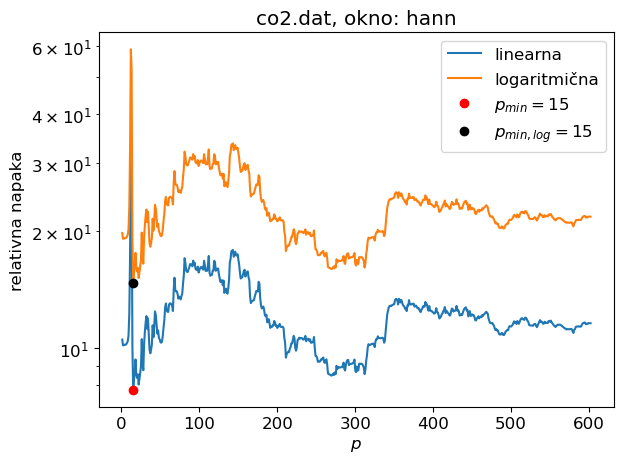

In [ ]:
p_min = err.index(min(err))
p_min_log = err_log.index(min(err_log))
if False:
    p_min = err.index(min(err[:dim//2]))
    p_min_log = err_log.index(min(err_log[:dim//2]))
print('minimum napake:', min(err), ', pri p =', p_min)
plt.plot(p,err,label='linearna')
plt.plot(p,err_log,label='logaritmična')
plt.plot(p[p_min], err[p_min], 'ro', label='$p_{min} = $'+str(p[p_min]))
plt.plot(p[p_min_log], err_log[p_min_log], 'ko', label='$p_{min,log} = $'+str(p[p_min_log]))
plt.xlabel('$p$')
plt.ylabel('relativna napaka')
plt.legend()
plt.yscale('log')
plt.xscale('linear')
if okno is not None:
    plt.title('co2.dat, okno: '+okno)
    plt.tight_layout()
    #plt.savefig('slike/napaka_co2_trend_'+okno+'.pdf')
else:
    plt.title('co2.dat, brez okna')
    plt.tight_layout()
    #plt.savefig('slike/napaka_co2.pdf')

### korak

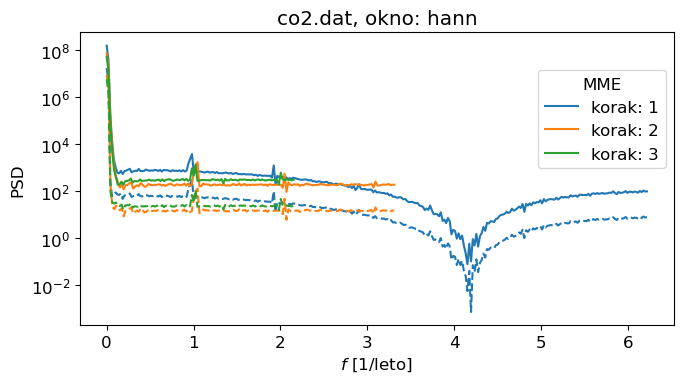

In [ ]:
okno = 'hann'
#okno = None
time_, data_ = np.loadtxt('podatki/co2.dat',unpack=True)
koraki=[1,2,3]
plt.figure(figsize=(7,4))

for korak in koraki:
    time = time_[::korak]
    data = data_[::korak]
    dim=len(data)
    order = dim-1
    dt = time[1] - time[0]
    if okno is not None:
        fourier = np.fft.fft(data*getattr(windows, okno)(dim))
    else:
        fourier = np.fft.fft(data)
    freq = np.fft.fftfreq(dim, d=dt)
    PSD_f = np.abs(fourier[:dim//2])**2/dim
    color = plt.gca()._get_lines.get_next_color()
    plt.plot(freq[:dim//2], PSD_f,'--',color=color)

    PSD_MME = PSD_co2(order,korak=korak,okno=okno,plot=False)
    plt.plot(freq[:dim//2], PSD_MME, '-', label='korak: '+str(korak),color=color) #TODO ista barva

    plt.yscale('log')
    legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='C0', linestyle='--', label='FFT    ')],
                                    bbox_to_anchor=(1.27,1))
    plt.gca().add_artist(legend_line_styles)
    plt.legend(title='MME', bbox_to_anchor=(1,0.9))
    if okno is not None:
        plt.title('co2.dat, okno: '+okno)
    else:
        plt.title('co2.dat, brez okna')
    plt.xlabel('$f$ [1/leto]')
    plt.ylabel('PSD')
    plt.tight_layout()
    plt.savefig('slike/PSD_co2_'+okno+'.pdf')

In [ ]:
okno = 'hann'
#okno = None
time_, data_ = np.loadtxt('podatki/co2.dat',unpack=True)
koraki=[1,2,3,4,5,6,7,8,9,10]
#koraki=[10]
order = 50
err=[]
err_log=[]  
for korak in koraki:
    time = time_[::korak]
    data = data_[::korak]
    dim=len(data)
    dt = time[1] - time[0]
    if okno is not None:
        fourier = np.fft.fft(data*getattr(windows, okno)(dim))
    else:
        fourier = np.fft.fft(data)
    freq = np.fft.fftfreq(dim, d=dt)
    PSD_f = np.abs(fourier[:dim//2])**2/dim

    PSD_MME = PSD_co2(order,korak=korak,okno=okno,plot=False)
    napaka = PSD_MME - PSD_f #shape!
    napaka_r = np.abs(np.sum(napaka)/np.sum(PSD_f))
    napaka_log = np.log10(PSD_MME - PSD_f) #logaritmična napaka
    napaka_log_r = np.abs(np.sum(napaka)/np.sum(np.log10(PSD_f)))
    err.append(napaka_r)
    err_log.append(napaka_log_r)

minimum napake: 1.609347477682833 , pri p = 0


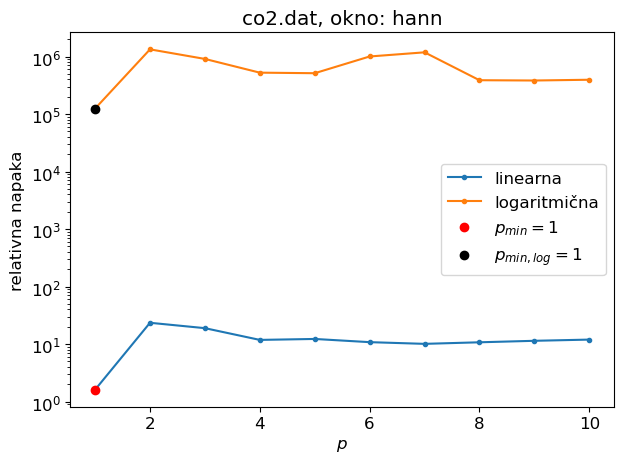

In [ ]:
p_min = err.index(min(err)) #p->korak
p_min_log = err_log.index(min(err_log))
if False:
    p_min = err.index(min(err[:dim//2]))
    p_min_log = err_log.index(min(err_log[:dim//2]))
print('minimum napake:', min(err), ', pri p =', p_min)
plt.plot(koraki,err,'.-',label='linearna')
plt.plot(koraki,err_log,'.-',label='logaritmična')
plt.plot(p[p_min], err[p_min], 'ro', label='$p_{min} = $'+str(p[p_min]))
plt.plot(p[p_min_log], err_log[p_min_log], 'ko', label='$p_{min,log} = $'+str(p[p_min_log]))
plt.xlabel('korak')
plt.ylabel('relativna napaka')
plt.legend()
plt.yscale('log')
plt.xscale('linear')
if okno is not None:
    plt.title('co2.dat, okno: '+okno)
    plt.tight_layout()
    #plt.savefig('slike/napaka_co2_'+okno+'.pdf')
else:
    plt.title('co2.dat, brez okna')
    plt.tight_layout()
    #plt.savefig('slike/napaka_co2.pdf')

# testni signal

In [8]:
def PSD_MME(data, order, okno=None):
    dim= len(data)
    
    if okno is not None:
        window = getattr(windows, okno)(dim)
        data = data * window

    p = pyule(data, order=order)
    p.run()
    px = p.get_converted_psd(sides='onesided')/dim
    #fx = p.frequencies(sides='onesided')        
    return px

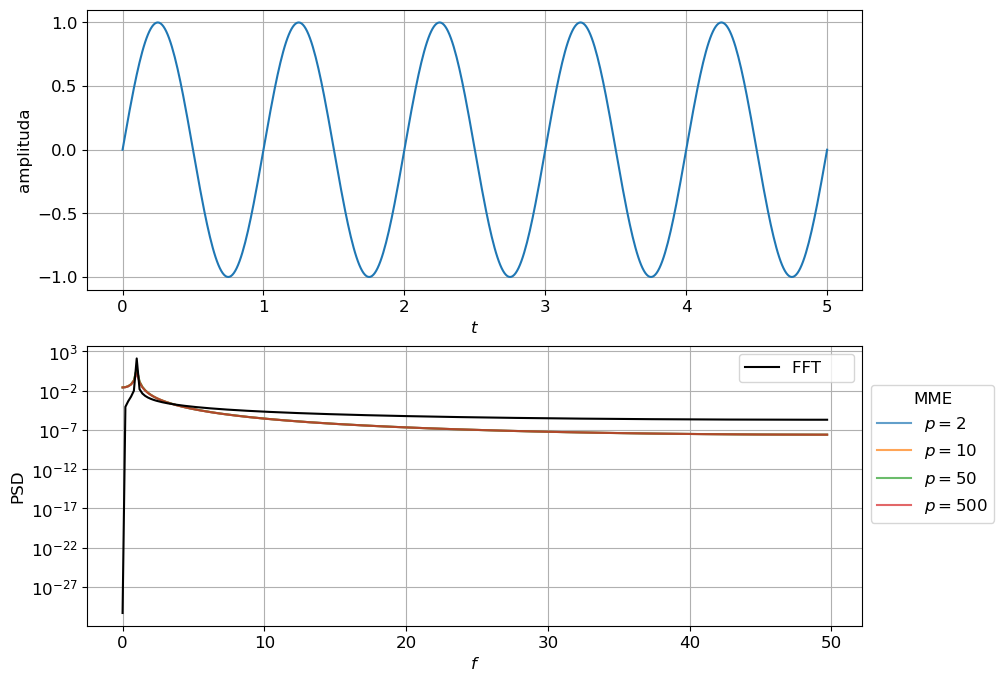

In [10]:
šum=0
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
x = np.linspace(0,5,501)
y = np.sin(2*np.pi*x)
if šum > 0:
        y += np.random.normal(scale=šum, size=len(y))

ax1.plot(x, y)
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.grid(True)

# x = np.linspace(0,2,100)
# y = np.sin(2*np.pi*x)
f=np.fft.fft(y)
freq = np.fft.fftfreq(len(y), d=x[1]-x[0])
PSD = np.abs(f)**2/len(y)

for order in [2,10,50, len(y)-1]:
    PSD_2 = PSD_MME(y, order=order)
    ax2.plot(freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')
ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.grid(True)
ax2.set_yscale('log')

#plt.savefig('slike/test_sin.pdf')
#plt.savefig('slike/test_sin_rms'+str(šum)+'.pdf')
plt.show()

### AM

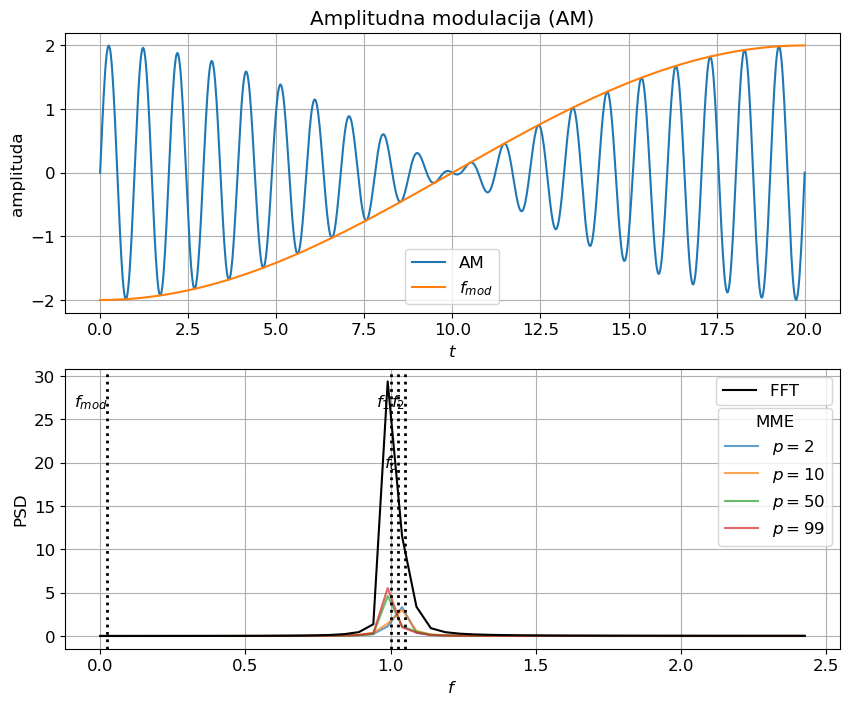

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
f1=1
f2=1.05
x=np.linspace(0,20,1000)
y=np.sin(2*np.pi*f1*x)+np.sin(2*np.pi*f2*x)
f_mod=np.abs(f1-f2)/2
f_c=(f1+f2)/2

ax1.plot(x, y, label='AM')
#ax1.plot(x, 2*np.sin(2*np.pi*x*f_c),label='$f_{c}$')
ax1.plot(x, 2*np.sin(2*np.pi*x*f_mod - np.pi/2),label='$f_{mod}$')
ax1.legend()
ax1.set_title('Amplitudna modulacija (AM)')
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.grid(True)

x=np.linspace(0,20,100)
y=np.sin(2*np.pi*f1*x)+np.sin(2*np.pi*f2*x)
f=np.fft.fft(y)
freq = np.fft.fftfreq(len(y), d=x[1]-x[0])
PSD = np.abs(f)**2/len(y)

for order in [2,10,50, len(y)-1]:
    PSD_2 = PSD_MME(y, order=order)
    ax2.plot(freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')

ax2.axvline(f1, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(f2, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(f_mod, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(f_c, color='k', linestyle='dotted',linewidth=2)
ax2.text(f1, 27, '$f_1$', color='k', ha='right', va='center')
ax2.text(f2, 27, '$f_2$', color='k', ha='right', va='center')
ax2.text(f_mod, 27, '$f_{mod}$', color='k', ha='right', va='center')
ax2.text(f_c, 20, '$f_{c}$', color='k', ha='right', va='center')

ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.grid(True)

#plt.savefig('slike/AM_še_bližnji_freq.pdf')
plt.show()

### FM

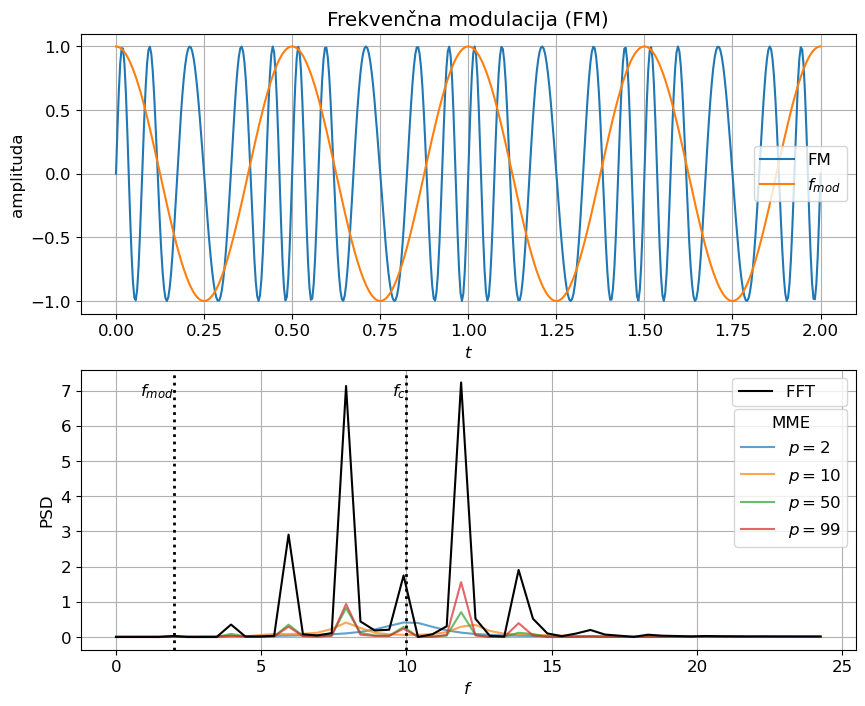

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
f_c = 10  # Carrier frequency
f_m = 2  # Modulating frequency
k_f = 2   # Frequency modulation index
x = np.linspace(0, 2, 500)
y = np.sin(2 * np.pi * f_c * x + k_f * np.sin(2 * np.pi * f_m * x))

ax1.plot(x, y, label='FM')
ax1.plot(x, np.sin(2*np.pi*f_m*x+np.pi/2),label='$f_{mod}$')
#ax1.plot(x, np.sin(2*np.pi*f_c*x),label='$f_{c}$')
ax1.legend()
ax1.set_title('Frekvenčna modulacija (FM)')
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.grid(True)

x = np.linspace(0,2,100)
y = np.sin(2 * np.pi * f_c * x + k_f * np.sin(2 * np.pi * f_m * x))
f=np.fft.fft(y)
freq = np.fft.fftfreq(len(y), d=x[1]-x[0])
PSD = np.abs(f)**2/len(y)

for order in [2,10,50, len(y)-1]:
    PSD_2 = PSD_MME(y, order=order)
    ax2.plot(freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')

ax2.axvline(f_c, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(f_m, color='k', linestyle='dotted',linewidth=2)
ax2.text(f_c, 7, '$f_c$', color='k', ha='right', va='center')
ax2.text(f_m, 7, '$f_{mod}$', color='k', ha='right', va='center')

ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.grid(True)

#plt.savefig('slike/FM.pdf')
plt.show()

### fazna modulacija (PM)

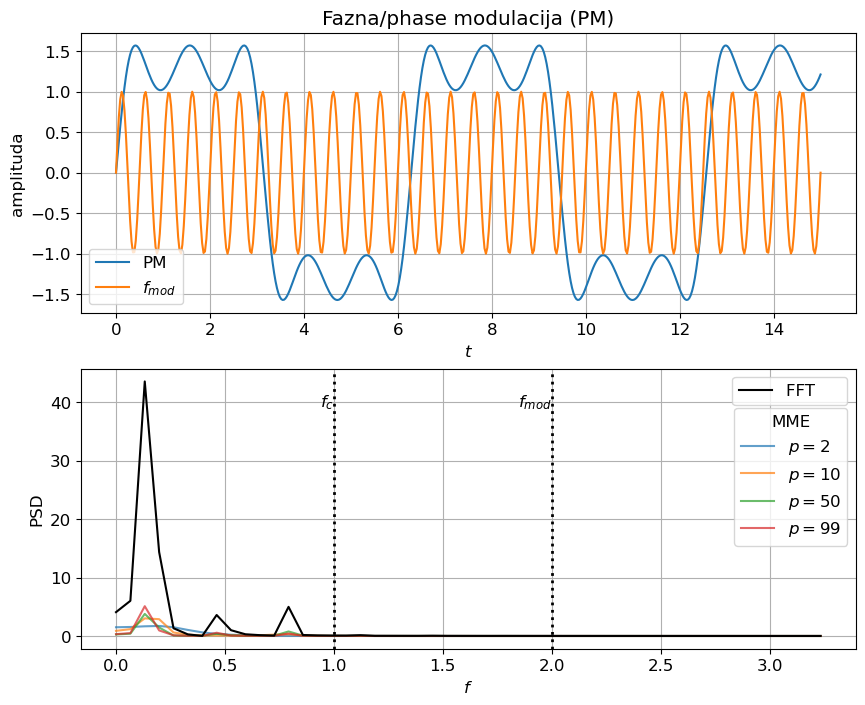

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
f1=1 #carrier
f2=2 #modulating frequency
x=np.linspace(0,15,500)
y=np.pi/2*np.sin(f1*x + np.pi/2*np.sin(f2*x))

ax1.plot(x, y, label='PM')
#ax1.plot(x, np.sin(2*np.pi*f1*x),label='$f_{c}$')
ax1.plot(x, np.sin(2*np.pi*f2*x),label='$f_{mod}$')
ax1.legend()
ax1.set_title('Fazna/phase modulacija (PM)')
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.grid(True)

x=np.linspace(0,15,100)
y=np.pi/2*np.sin(f1*x + np.pi/2*np.sin(f2*x))
f=np.fft.fft(y)
freq = np.fft.fftfreq(len(y), d=x[1]-x[0])
PSD = np.abs(f)**2/len(y)

for order in [2,10,50, len(y)-1]:
    PSD_2 = PSD_MME(y, order=order)
    ax2.plot(freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')

ax2.axvline(f1, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(f2, color='k', linestyle='dotted',linewidth=2)
ax2.text(f1, 40, '$f_c$', color='k', ha='right', va='center')
ax2.text(f2, 40, '$f_{mod}$', color='k', ha='right', va='center')

ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.grid(True)

#plt.savefig('slike/PM.pdf')
plt.show()

# wolf

/tmp/ipykernel_14868/2239356930.py:21: RuntimeWarning: divide by zero encountered in divide
  ax2.plot(1/freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))
/tmp/ipykernel_14868/2239356930.py:23: RuntimeWarning: divide by zero encountered in divide
  ax2.plot(1/freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')


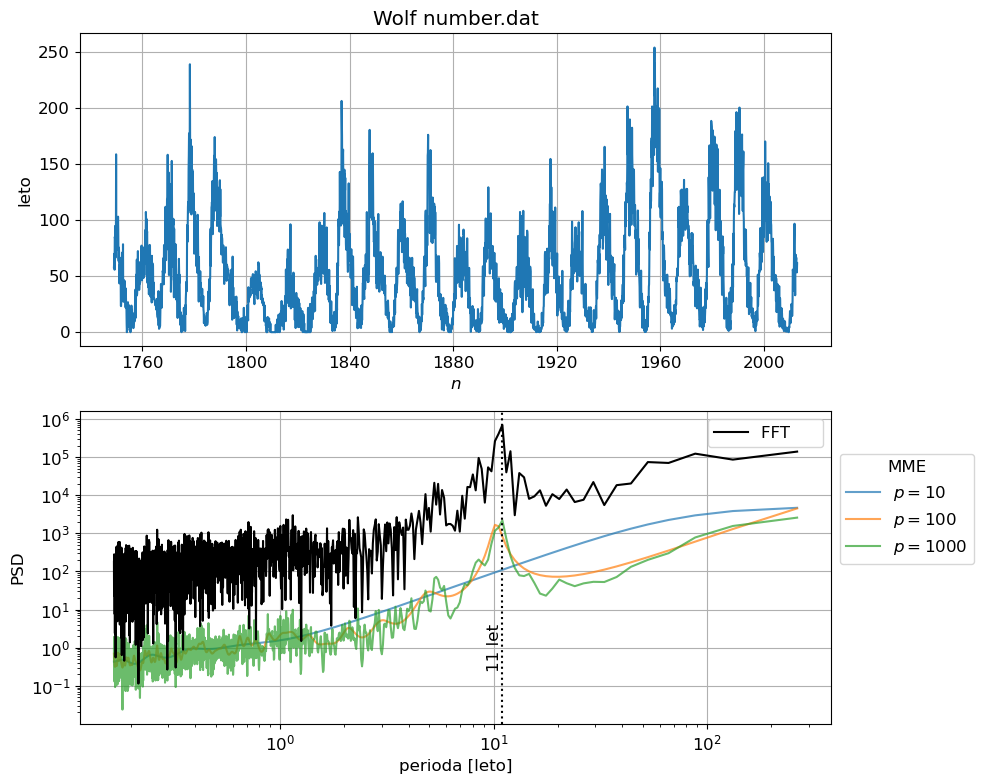

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
year,month,y = np.loadtxt('podatki/Wolf_number.dat',unpack=True)
dim=len(y)
dates = [datetime(int(year[i]), int(month[i]), 1) for i in range(dim)]
time_intervals = np.array([(dates[i + 1] - dates[i]).days/ 365.25 for i in range(dim - 1)])
dim=len(y)
x=np.linspace(0,dim-1,dim)

ax1.plot(dates, y)
ax1.set_title('Wolf number.dat')
ax1.set_xlabel('$n$')
ax1.set_ylabel('leto')
ax1.grid(True)

f=np.fft.fft(y)
freq = np.fft.fftfreq(len(y), d=time_intervals.mean())
PSD = np.abs(f)**2/len(y)

for order in [10,100, 1000]:
    PSD_2 = PSD_MME(y, order=order)
    ax2.plot(1/freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(1/freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')

ax2.axvline(11, color='k', linestyle='dotted')
ax2.text(11, 1, '11 let', color='k', ha='right', va='center', rotation='vertical')

ax2.set_xlabel('perioda [leto]')
ax2.set_ylabel('PSD')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.grid(True)

plt.tight_layout()
#plt.savefig('slike/wolf_PSD.pdf')
plt.show()

# luna

/tmp/ipykernel_14868/3924259596.py:18: RuntimeWarning: divide by zero encountered in divide
  ax2.plot(1/freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))
/tmp/ipykernel_14868/3924259596.py:20: RuntimeWarning: divide by zero encountered in divide
  ax2.plot(1/freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')


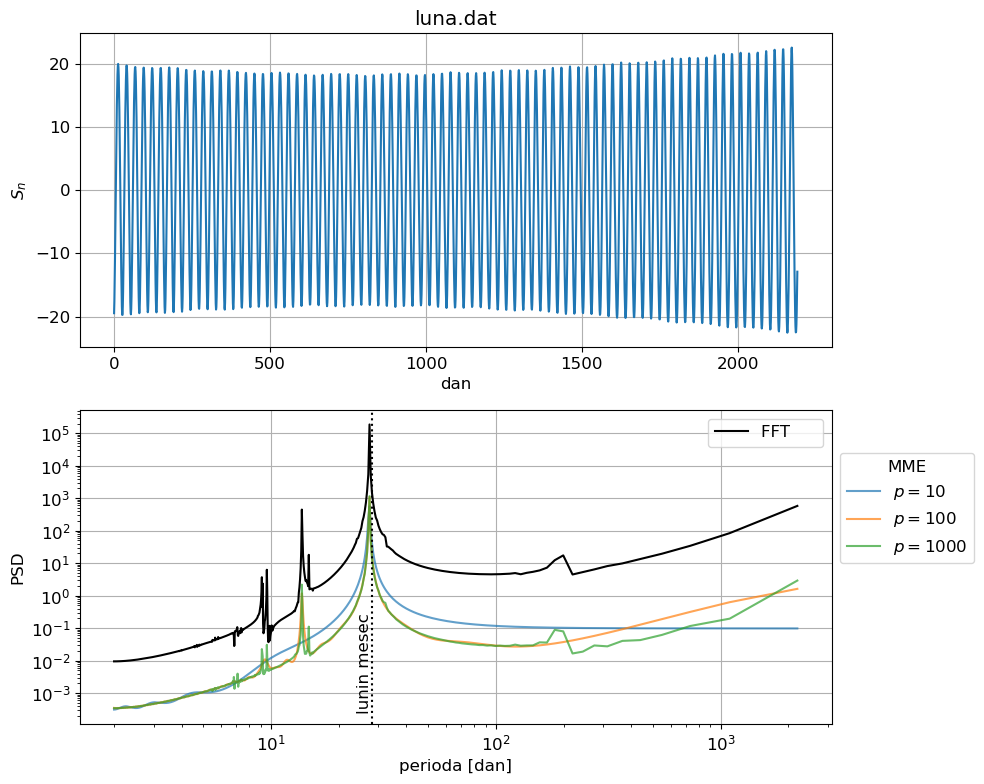

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
y = np.loadtxt('podatki/luna.dat', usecols=(2))
dim=len(y)
x=np.linspace(0,dim-1,dim) #days

ax1.plot(x, y)
ax1.set_title('luna.dat')
ax1.set_xlabel('dan')
ax1.set_ylabel('$S_n$')
ax1.grid(True)

f=np.fft.fft(y)
freq = np.fft.fftfreq(len(y), d=x[1]-x[0])
PSD = np.abs(f)**2/len(y)

for order in [10,100, 1000]:
    PSD_2 = PSD_MME(y, order=order)
    ax2.plot(1/freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(1/freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')

ax2.axvline(28, color='k', linestyle='dotted')
ax2.text(28, 0.008, 'lunin mesec', color='k', ha='right', va='center', rotation='vertical')

ax2.set_xlabel('perioda [dan]')
ax2.set_ylabel('PSD')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.grid(True)

plt.tight_layout()
#plt.savefig('slike/luna_PDS.pdf')
plt.show()

# borza

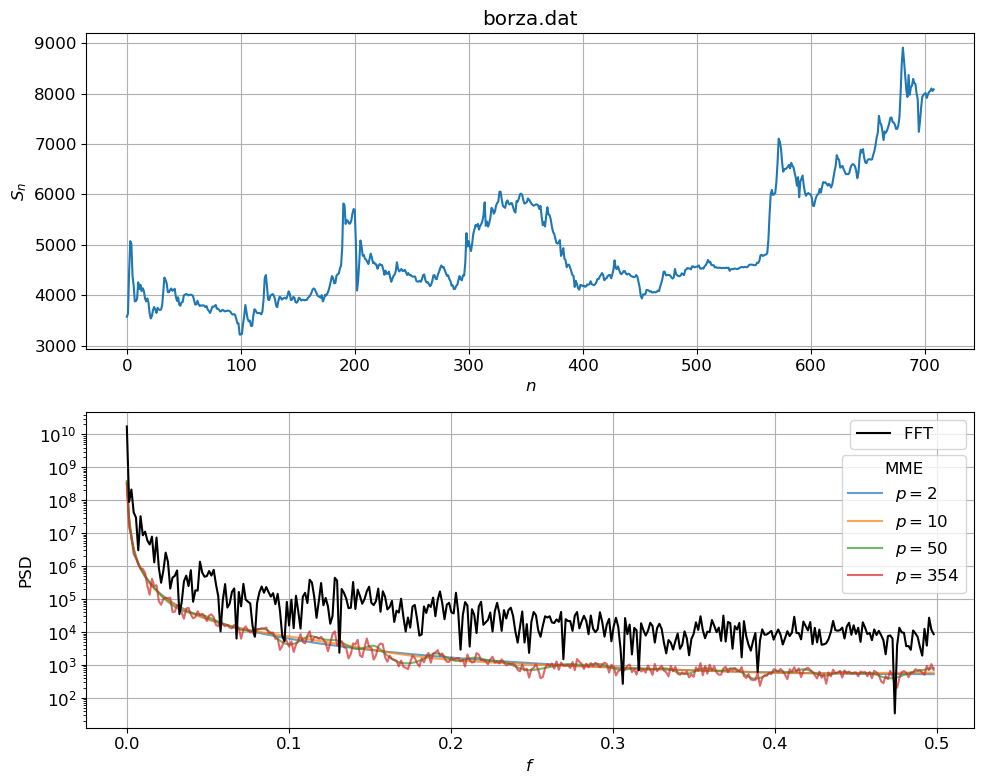

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
y = np.loadtxt('podatki/borza.dat')
dim=len(y)
x=np.linspace(0,dim-1,dim) #days

ax1.plot(x, y)
ax1.set_title('borza.dat')
ax1.set_xlabel('$n$')
ax1.set_ylabel('$S_n$')
ax1.grid(True)

f=np.fft.fft(y)
freq = np.fft.fftfreq(len(y), d=x[1]-x[0])
PSD = np.abs(f)**2/len(y)

for order in [2,10,50, len(y)//2]:
    PSD_2 = PSD_MME(y, order=order)
    ax2.plot(freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(freq[:len(y) // 2], PSD[:len(y) // 2], 'k-')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')

ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
# ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.grid(True)

plt.tight_layout()
#plt.savefig('slike/borza_PSD.pdf')
plt.show()

# temperatura

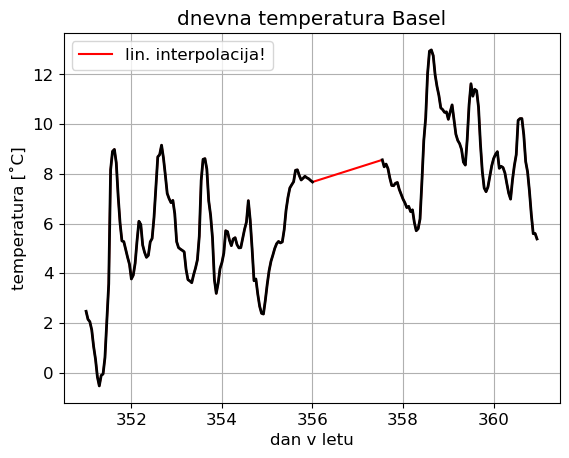

In [16]:
convert_nan = lambda x: np.nan if x.strip() == b'' else float(x)
y = np.loadtxt('podatki/temp.csv', skiprows=10, usecols=1, delimiter=',', converters={1: convert_nan})
dim=len(y)
x=np.linspace(0,dim-1,dim) #hours
days = x/24+1
y_interp = np.interp(x, np.where(~np.isnan(y))[0], y[~np.isnan(y)])

n=10 #prikaz dni
z=350 #zamik dni
plt.plot(days[z*24:z*24+24*n], y_interp[z*24:z*24+24*n],'r',label='lin. interpolacija!')
plt.plot(days[z*24:z*24+24*n], y[z*24:z*24+24*n], 'k', linewidth=2)
plt.xlabel('dan v letu')
plt.ylabel('temperatura [˚C]')
plt.grid()
plt.title('dnevna temperatura Basel')
plt.legend(loc='best')
#plt.savefig('slike/dnevna_temp.pdf')

/tmp/ipykernel_154769/73987904.py:14: RuntimeWarning: divide by zero encountered in divide
  ax2.plot(1/freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))
/tmp/ipykernel_154769/73987904.py:16: RuntimeWarning: divide by zero encountered in divide
  ax2.plot(1/freq[:len(y) // 2], PSD[:len(y) // 2], 'b-', alpha=0.6)


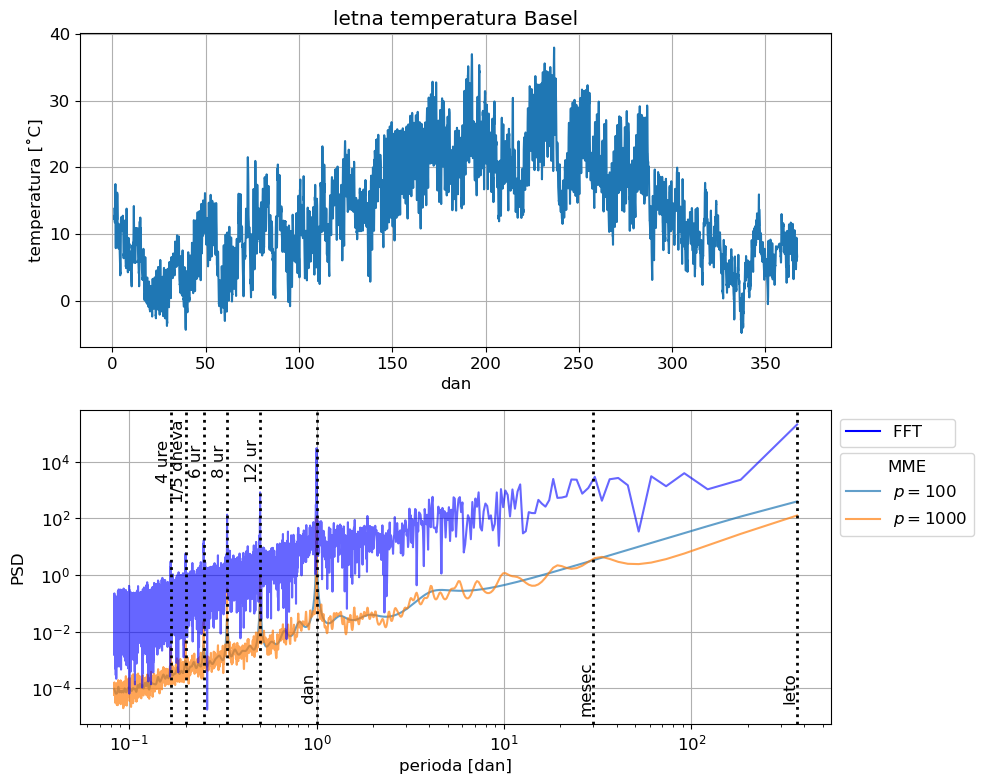

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.plot(days, y_interp)
ax1.set_title('letna temperatura Basel')
ax1.set_xlabel('dan')
ax1.set_ylabel('temperatura [˚C]')
ax1.grid(True)

f=np.fft.fft(y_interp)
freq = np.fft.fftfreq(len(y), d=days[1]-days[0])
PSD = np.abs(f)**2/len(y)

for order in [100,1000]:
    PSD_2 = PSD_MME(y_interp, order=order)
    ax2.plot(1/freq[:len(y) // 2], PSD_2[:len(y) // 2]/len(y), alpha=0.7,label='$p=$'+str(order))

ax2.plot(1/freq[:len(y) // 2], PSD[:len(y) // 2], 'b-', alpha=0.6)
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='b', linestyle='-', label='FFT     ')],
                                bbox_to_anchor=(1,1))
plt.gca().add_artist(legend_line_styles)
ax2.legend(title='MME', bbox_to_anchor=(1,0.89),loc='best')

ax2.axvline(1/6, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(1/5, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(0.25, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(1/3, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(0.5, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(1, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(30, color='k', linestyle='dotted',linewidth=2)
ax2.axvline(365, color='k', linestyle='dotted',linewidth=2)
ax2.text(1/6, 10000, '4 ure', color='k', ha='right', va='center', rotation='vertical')
ax2.text(1/5, 10000, '1/5 dneva', color='k', ha='right', va='center', rotation='vertical')
ax2.text(0.25, 10000, '6 ur', color='k', ha='right', va='center', rotation='vertical')
ax2.text(1/3, 10000, '8 ur', color='k', ha='right', va='center', rotation='vertical')
ax2.text(0.5, 10000, '12 ur', color='k', ha='right', va='center', rotation='vertical')
ax2.text(1, 0.0001, 'dan', color='k', ha='right', va='center', rotation='vertical')
ax2.text(30, 0.0001, 'mesec', color='k', ha='right', va='center', rotation='vertical')
ax2.text(365, 0.0001, 'leto', color='k', ha='right', va='center', rotation='vertical')

ax2.set_xlabel('perioda [dan]')
ax2.set_ylabel('PSD')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.grid(True)

plt.tight_layout()
#plt.savefig('slike/letna_temp_PSD.pdf')
plt.show()